# 02 – Data access, AOIs and seasonal composites (Sentinel-2)

**Project:** Beech dieback after the 2018 drought – Sentinel-2 first, high-resolution NIR later.
**Goal of this notebook:** define three AOIs, access Sentinel-2 L2A, build cloud-masked seasonal composites, add ancillary layers (forest mask, DEM) and check that the AOIs are comparable.

| AOI | Key | Role | Why |
|---|---|---|---|
| Ajoie (JU) | `ajoie_ju` | target / out-of-region test | Beech dieback hotspot; study area of swisstopo/STDL *CLASSIFY – Gesundheitsgrad von Buchen* (project HETRES) |
| Fricktal / Tafeljura (AG) | `fricktal_ag` | training / validation | Comparable limestone, beech-dominated Jura-type forest, similar elevation range |
| Rhone valley (VS) | `valais_rhone` | domain-shift test | Drier inner-alpine valley (Pfynwald area). Mostly Scots pine/oak, so it tests transferability rather than a like-for-like beech case |

**Data:** Sentinel-2 L2A from the Microsoft Planetary Computer STAC (no login), 10 m grid in EPSG:32632.
**Caveat:** the bounding boxes are approximate. Replace them with the STDL HETRES polygons or forest-service stand maps once available (see `AOIS` in `scripts/sds_utils.py`).

*Context:* swisstopo/STDL describe beech dieback in the Ajoie since the 2018 drought and used a Random Forest on LiDAR, aerial-image (RGB/NIR, 3 cm) and Sentinel-2 NDVI descriptors; the annual NDVI change 2018→2019 was among the most important predictors (swisstopo 2025, see references).

In [1]:
import sys, warnings
from pathlib import Path
sys.path.append(str(Path("..").resolve() / "scripts"))   # folder containing sds_utils.py

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

import sds_utils as su
warnings.filterwarnings("ignore", category=FutureWarning)

# Years: 2017 = pre-drought baseline, 2018 = drought, 2019-2020 = lagged mortality, later = recovery / current state.
# Reduce the list for a faster first run (each AOI-year-window is one composite).
YEARS = [2017, 2018, 2019, 2020, 2022, 2024, 2025, 2026]
print("project root:", su.ROOT)
print("windows:", su.WINDOWS)

project root: /Users/davidleu/Desktop/sds320-project
windows: {'peak': ('06-15', '07-31'), 'late': ('08-15', '09-30')}


## 1 · Areas of interest

In [2]:
aois = su.aoi_gdf()
display(aois[["aoi", "label", "role", "area_km2"]].round(1))
m = aois.explore(column="aoi", categorical=True, tiles="https://wmts.geo.admin.ch/1.0.0/ch.swisstopo.pixelkarte-farbe/default/current/3857/{z}/{x}/{y}.jpeg", attr="© swisstopo",
                 style_kwds=dict(fillOpacity=0.25), tooltip=["label", "role", "area_km2"])
m.save(su.FIGS / "02_aois.html")      # standalone copy of the map
m

,aoi,label,role,area_km2
0,ajoie_ju,Ajoie (JU),target / out-of-region test,166.0
1,fricktal_ag,Fricktal / Tafeljura (AG),train / validation,156.6
2,valais_rhone,Rhone valley (VS),domain-shift test,171.2


## 2 · Scene availability
Search only (no download). Counts are items per window; an AOI that straddles a tile border can return several items per date.

In [3]:
rows = []
for aoi, cfg in su.AOIS.items():
    for y in YEARS:
        for w, (d0, d1) in su.WINDOWS.items():
            items = su.search_s2(cfg["bbox"], f"{y}-{d0}", f"{y}-{d1}", max_cloud=70)
            cc = [i.properties["eo:cloud_cover"] for i in items]
            rows.append(dict(aoi=aoi, year=y, window=w, n_items=len(items),
                             min_cloud=min(cc) if cc else np.nan))
avail = pd.DataFrame(rows)
avail.to_csv(su.TABLES / "scene_availability.csv", index=False)
avail.pivot_table(index=["aoi", "window"], columns="year", values="n_items")

year                 2017  2018  2019  2020  2022  2024  2025  2026
aoi          window                                                
ajoie_ju     late    11.0  16.0  15.0  10.0  24.0  10.0  23.0  16.0
             peak    11.0  17.0  18.0  17.0  22.0   8.0  20.0  22.0
fricktal_ag  late    12.0  14.0  15.0  11.0  20.0   9.0  12.0  18.0
             peak    13.0  15.0  14.0  15.0  29.0  11.0  14.0  24.0
valais_rhone late    24.0  34.0  29.0  29.0  47.0  20.0  40.0  40.0
             peak    25.0  33.0  33.0  32.0  52.0  26.0  34.0  50.0

## 3 · One test composite
Cloud masking uses the Sen2Cor scene classification layer (SCL); the composite is the per-pixel **median** of valid observations in the window. The +1000 DN offset of processing baseline ≥ 04.00 is handled in `composite_s2`.

**Implementation note.** Scenes are read band by band as windowed COG reads with `rasterio` (`WarpedVRT`) in a thread pool. The first version used `odc-stac` + dask and hung on the Ajoie, which straddles two MGRS tiles (31TGN in UTM 31N, 32TLT in UTM 32N). One composite now takes about a minute; the whole set (3 AOIs × 8 years × 2 windows) about 45 minutes on first run and seconds afterwards (cached). `python scripts/build_composites.py` does the same from the terminal.

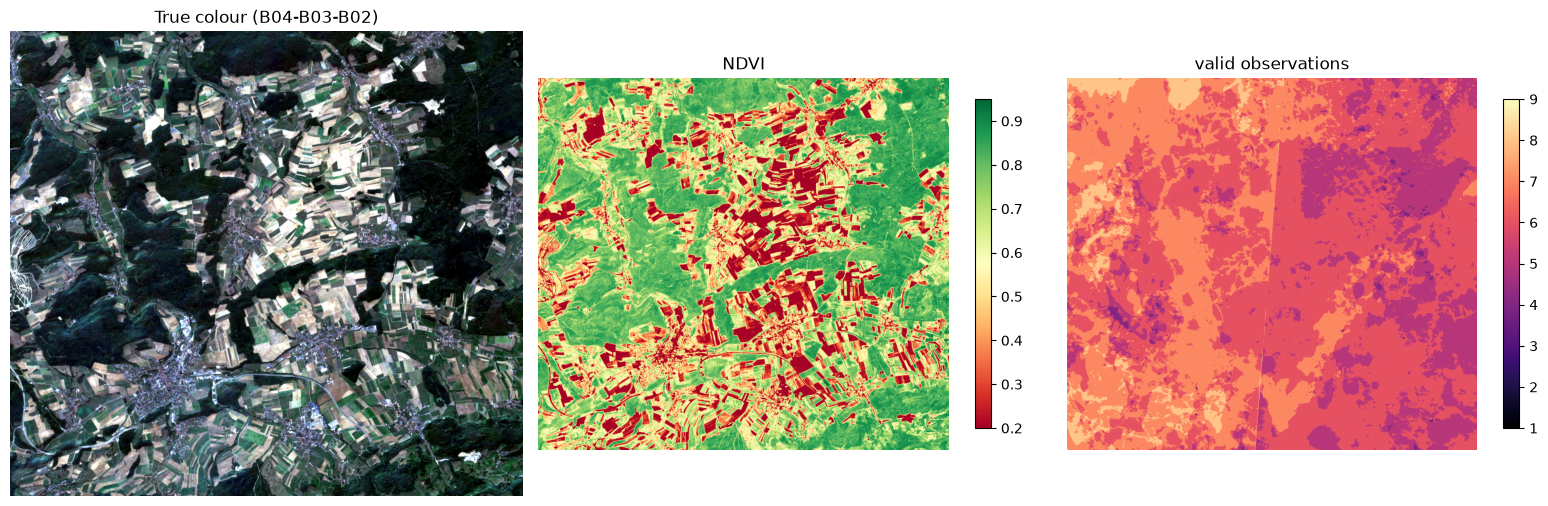

['n_obs', 'B02', 'B03', 'B04', 'B05', 'B07', 'B08', 'B8A', 'B11', 'B12', 'NDVI', 'NDRE', 'CIre', 'NDMI', 'NBR', 'spatial_ref']


In [4]:
comp = su.build_composite("ajoie_ju", 2018, "late")
fig, ax = plt.subplots(1, 3, figsize=(16, 5))
ax[0].imshow(su.rgb(comp)); ax[0].set_title("True colour (B04-B03-B02)")
im = ax[1].imshow(comp["NDVI"], cmap="RdYlGn", vmin=0.2, vmax=0.95); ax[1].set_title("NDVI")
plt.colorbar(im, ax=ax[1], shrink=0.7)
im = ax[2].imshow(comp["n_obs"], cmap="magma"); ax[2].set_title("valid observations")
plt.colorbar(im, ax=ax[2], shrink=0.7)
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()
print(list(comp.data_vars))

## 4 · Build all composites
Cached as NetCDF in `data/derived.nosync/` (existing files are skipped). Failed combinations are logged, not fatal.

In [5]:
log = []
for aoi in su.AOIS:
    for y in YEARS:
        for w in su.WINDOWS:
            try:
                cmp_ = su.build_composite(aoi, y, w)
                log.append(dict(aoi=aoi, year=y, window=w, ok=True,
                                n_scenes=cmp_.attrs.get("n_scenes"),
                                valid_frac=float((cmp_["n_obs"] > 0).mean()),
                                median_nobs=float(cmp_["n_obs"].median())))
            except Exception as e:
                log.append(dict(aoi=aoi, year=y, window=w, ok=False, error=str(e)[:100]))
inv = pd.DataFrame(log)
inv.to_csv(su.TABLES / "composite_inventory.csv", index=False)
display(inv[~inv.ok] if (~inv.ok).any() else "all composites built")
inv[inv.ok].pivot_table(index=["aoi", "window"], columns="year", values="valid_frac").round(2)

'all composites built'

year                 2017  2018  2019  2020  2022  2024  2025  2026
aoi          window                                                
ajoie_ju     late     1.0   1.0   1.0   1.0   1.0  0.99   1.0   1.0
             peak     1.0   1.0   1.0   1.0   1.0  0.85   1.0   1.0
fricktal_ag  late     1.0   1.0   1.0   1.0   1.0  1.00   1.0   1.0
             peak     1.0   1.0   1.0   1.0   1.0  0.98   1.0   1.0
valais_rhone late     1.0   1.0   1.0   1.0   1.0  1.00   1.0   1.0
             peak     1.0   1.0   1.0   1.0   1.0  1.00   1.0   1.0

## 5 · Ancillary layers and AOI comparability
- **Forest mask:** ESA WorldCover 2021, class 10 (tree cover), shrunk by one pixel so that only interior forest pixels remain (`forest`; the full mask is kept as `forest_all`). Edge pixels mix canopy with fields and roads and produced false change in a first run. The mask does **not** separate beech from other species. A species or mixture layer (e.g. FOEN/WSL forest maps) is a planned refinement.
- **Terrain:** Copernicus DEM GLO-30 resampled to 10 m, slope and aspect derived.

In [6]:
anc = {}
for aoi in su.AOIS:
    anc[aoi] = su.load_ancillary(aoi)             # same 10 m grid as the composites

rows = []
for aoi, a in anc.items():
    f = a["forest"].values == 1
    e, s = a["elevation"].values[f], a["slope"].values[f]
    rows.append(dict(aoi=aoi, forest_km2=f.sum() * 100 / 1e6, forest_frac=f.mean(),
                     elev_p10=np.percentile(e, 10), elev_median=np.median(e), elev_p90=np.percentile(e, 90),
                     slope_median=np.median(s)))
cmp_tbl = pd.DataFrame(rows).set_index("aoi").round(2)
cmp_tbl

,forest_km2,forest_frac,elev_p10,elev_median,elev_p90,slope_median
aoi,,,,,,
ajoie_ju,66.92,0.38,452.959991,496.670013,583.229980,10.680000
fricktal_ag,67.15,0.42,0.000000,464.910004,697.690002,7.400000
valais_rhone,84.36,0.47,649.770020,1198.459961,1868.020020,28.559999


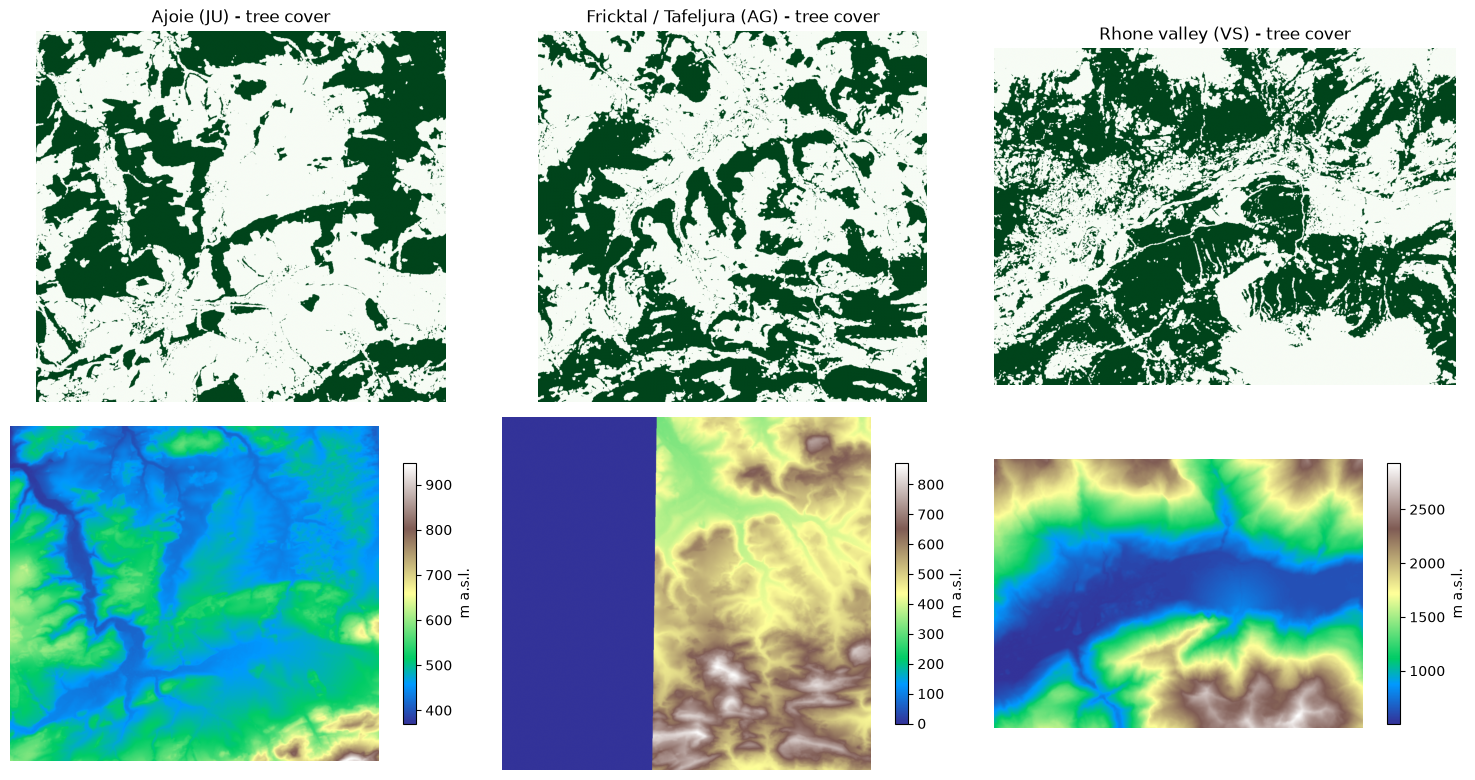

In [7]:
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for j, (aoi, a) in enumerate(anc.items()):
    ax[0, j].imshow(a["forest"], cmap="Greens", vmin=0, vmax=1); ax[0, j].set_title(f"{su.AOIS[aoi]['label']} - tree cover")
    im = ax[1, j].imshow(a["elevation"], cmap="terrain"); plt.colorbar(im, ax=ax[1, j], shrink=0.7, label="m a.s.l.")
    ax[0, j].axis("off"); ax[1, j].axis("off")
plt.tight_layout(); plt.savefig(su.FIGS / "02_aoi_overview.png", dpi=150); plt.show()

## 6 · Notes for the next steps
- Check `composite_inventory.csv`: composites with a low `valid_frac` (cloudy windows) should be widened or dropped before change analysis.
- Late-season windows are the most useful for premature senescence, but they also have the highest phenology noise; compare 2017 vs 2018 vs 2019 only within the same window.
- AOI boxes and the forest mask are first approximations. Beech-specific masks and field labels are needed for the training notebook (04).

## References
- swisstopo (2025): *CLASSIFY – Gesundheitsgrad von Buchen*. https://www.swisstopo.admin.ch/de/classify-gesundheitsgrad-von-buchen (technical doc: STDL PROJ-HETRES, https://tech.stdl.ch/PROJ-HETRES/)
- Frei, E.R. et al. (2022): European beech dieback after premature leaf senescence during the 2018 drought in northern Switzerland. *Plant Biology* 24(7), 1132–1145.
- Brun, P. et al. (2020): Large-scale early-wilting response of Central European forests to the 2018 extreme drought. *Global Change Biology* 26(12), 7021–7035.
- Rouse, J.W. et al. (1974) NDVI; Gitelson & Merzlyak (1994) NDRE; Gitelson et al. (2003) CIre; Wilson & Sader (2002) NDMI; Key & Benson (2006) NBR.
- Microsoft Planetary Computer STAC (Sentinel-2 L2A, ESA WorldCover, Copernicus DEM GLO-30).